# View-flexible keratoconus detection: train on Pentacam, validate on Orbscan

**Protocol.** Pentacam (7 maps/case) is used for training, validation and an internal test. Orbscan (4 maps/eye) is external: never used for training, model selection or threshold choice, and evaluated once with a fixed threshold of 0.5. Only the few-shot section (§8) uses a handful of labelled Orbscan eyes, and those patients are removed from the evaluation. Map correspondence is an assumption: Sag_A↔Axial, Elv_A↔Anterior, Elv_P↔Posterior, CT_A↔Pachymetry.

Figures are saved one file per figure in `figures/` (PNG 300 dpi + PDF), tables in `tables/`. The last cell zips everything.

In [1]:
import os, time, random, copy, itertools, json, zipfile, warnings
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import torch, torch.nn as nn, torch.nn.functional as F
import timm
from PIL import Image
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.manifold import TSNE
from sklearn.metrics import (accuracy_score, roc_auc_score, f1_score, matthews_corrcoef,
                             confusion_matrix, roc_curve, brier_score_loss)
warnings.filterwarnings("ignore")

ROOT = Path("/kaggle/input/datasets/nasiruddin66/keratoconus-datasets-2/Keratoconus datasets 2")      # folder containing Pentacam_Dataset/ and ORBSCAN_Dataset/
OUT = Path("/kaggle/working/results")

SEED = 42                      # seed of the main model and of the CV fold split
SEEDS = [42, 43, 44]           # ablation variants are repeated over these seeds
IMG = 224
BACKBONES = ["resnet50", "efficientnet_b0", "convnext_tiny", "densenet121", "swin_tiny_patch4_window7_224"]
EPOCHS, EPOCHS_REV = 25, 12    # fixed budgets; no best-epoch selection on held-out data
BATCH = 16
LR_BB, LR_HEAD = 1e-4, 5e-4
P_ALL, P_MATCHED = 0.25, 0.35  # view dropout: P(all 7 views), P(the 4 Orbscan-matched views), else random subset
PRETRAINED = True
FOLDS = [1, 2, 3, 4, 5]
N_BOOT = 1000
N_DRAWS = 200                  # random draws for few-shot calibration
SHOTS = [0, 10, 20, 50, 100]
RUN_REVERSE = True             # Orbscan -> Pentacam direction (Table 4)
INCLUDE_WEIGHTS = False        # add model weights to the zip (large)

FIG, TAB, PRD, CACHE = [OUT / d for d in ("figures", "tables", "predictions", "cache")]
for d in (FIG, TAB, PRD, CACHE): d.mkdir(parents=True, exist_ok=True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
USE_AMP = DEVICE == "cuda"

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(SEED)

COL = dict(normal="#0072B2", kc="#D55E00", pen="#0072B2", orb="#D55E00", grey="#8C8C8C", green="#009E73", pink="#CC79A7", gold="#E69F00")
CFG_COL = dict(FULL="#D55E00", noViewDrop="#0072B2", noStyle="#009E73", meanPool="#CC79A7", matched4="#8C8C8C")
plt.rcParams.update({"figure.dpi": 120, "font.size": 9, "axes.titlesize": 9, "axes.labelsize": 9, "legend.fontsize": 8,
                     "xtick.labelsize": 8, "ytick.labelsize": 8, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "axes.axisbelow": True, "pdf.fonttype": 42})

def savefig(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=300, bbox_inches="tight"); fig.savefig(FIG / f"{name}.pdf", bbox_inches="tight")
    plt.show()

TABLES = {}
def keep(name, df):
    TABLES[name] = df; df.to_csv(TAB / f"{name}.csv"); return df

def find(name):
    for d in (CACHE, OUT):
        if (d / name).exists(): return d / name
    return None
print(DEVICE, torch.__version__, timm.__version__)

cuda 2.11.0+cu128 1.0.29


## 1. Data

In [2]:
PEN, ORB = ROOT / "Pentacam_Dataset", ROOT / "ORBSCAN_Dataset"
PEN_VIEWS = ["Sag_A", "Elv_A", "Elv_P", "CT_A", "EC_A", "EC_P", "Sag_P"]
ORB_VIEWS = ["Axial", "Anterior", "Posterior", "Pachymetry"]

rows = []
for split, tag in [("Train_Validation_Set", "tv"), ("Independent_Test_Set", "test")]:
    for cls, lab, pre in [("Normal", 0, "NOR"), ("Keratoconus", 1, "KCN")]:
        for case in sorted(p for p in (PEN / split / cls).iterdir() if p.is_dir()):
            n = case.name.replace("case", "")
            r = dict(split=tag, label=lab, case_id=f"{tag}_{pre}_{n}")
            for v in PEN_VIEWS: r[v] = str((case / f"{pre}_{n}_{v}.jpg").relative_to(ROOT))
            rows.append(r)
pen = pd.DataFrame(rows)

rows = []
for cls, lab in [("Normal", 0), ("Keratoconus", 1)]:
    for pat in sorted(p for p in (ORB / cls).iterdir() if p.is_dir()):
        for eye in sorted(p for p in pat.iterdir() if p.is_dir()):
            r = dict(label=lab, patient=pat.name, eye=eye.name, eye_id=f"{pat.name}_{eye.name}")
            for v in ORB_VIEWS: r[v] = str((eye / f"{pat.name}_{eye.name}_{v}.png").relative_to(ROOT))
            rows.append(r)
orb = pd.DataFrame(rows)

miss = [p for v in PEN_VIEWS for p in pen[v] if not (ROOT / p).exists()] + [p for v in ORB_VIEWS for p in orb[v] if not (ROOT / p).exists()]
assert not miss, f"{len(miss)} files missing, e.g. {miss[:3]}"

tv, te = np.where(pen.split == "tv")[0], np.where(pen.split == "test")[0]
y_pen, y_orb, g_orb = pen.label.values, orb.label.values, orb.patient.values
y_tv, y_te = y_pen[tv], y_pen[te]
ALL_ORB, ALL_PEN = np.arange(len(orb)), np.arange(len(pen))

# Folds are drawn by case. Pentacam case IDs carry no patient information, so both eyes of one
# patient could in principle sit in different cases; this is stated as a limitation.
fold_tv = np.zeros(len(tv), int)
for k, (_, va) in enumerate(StratifiedKFold(5, shuffle=True, random_state=SEED).split(tv, y_tv), 1): fold_tv[va] = k
ran = np.isin(fold_tv, FOLDS)
pd.DataFrame({"case_id": pen.case_id.values[tv], "label": y_tv, "fold": fold_tv}).to_csv(TAB / "pentacam_folds.csv", index=False)

t1 = pd.concat({
    "Pentacam train/validation (cases)": pen[pen.split == "tv"].groupby("label").size(),
    "Pentacam independent test (cases)": pen[pen.split == "test"].groupby("label").size(),
    "Orbscan external (eyes)": orb.groupby("label").size(),
    "Orbscan external (patients)": orb.groupby("label").patient.nunique()}, axis=1).T
t1.columns = ["Normal", "Keratoconus"]; t1["Total"] = t1.sum(1)
t1.loc["Orbscan external (patients)", "Total"] = orb.patient.nunique()
keep("table1_datasets", t1)

,Normal,Keratoconus,Total
Pentacam train/validation (cases),150,150,300
Pentacam independent test (cases),50,50,100
Orbscan external (eyes),886,521,1407
Orbscan external (patients),446,298,744


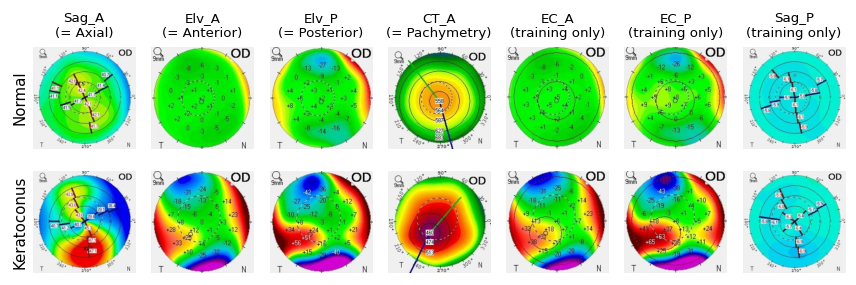

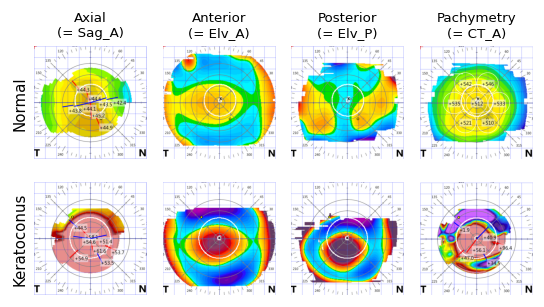

In [3]:
def view_grid(df, views, titles, name, size_w):
    r_n, r_k = df[df.label == 0].iloc[0], df[df.label == 1].iloc[0]
    fig, ax = plt.subplots(2, len(views), figsize=(size_w, size_w / len(views) * 2 + .5))
    for i, (r, lab) in enumerate([(r_n, "Normal"), (r_k, "Keratoconus")]):
        for j, v in enumerate(views):
            ax[i, j].imshow(Image.open(ROOT / r[v]).convert("RGB")); ax[i, j].axis("off"); ax[i, j].grid(False)
            if i == 0: ax[i, j].set_title(titles[j], fontsize=8)
        ax[i, 0].text(-.06, .5, lab, transform=ax[i, 0].transAxes, rotation=90, va="center", ha="right", fontsize=9)
    plt.tight_layout(); savefig(fig, name)

view_grid(pen[pen.split == "tv"], PEN_VIEWS, [f"{v}\n(= {ORB_VIEWS[i]})" if i < 4 else f"{v}\n(training only)" for i, v in enumerate(PEN_VIEWS)], "fig02_pentacam_views", 7.2)
view_grid(orb, ORB_VIEWS, [f"{v}\n(= {PEN_VIEWS[i]})" for i, v in enumerate(ORB_VIEWS)], "fig03_orbscan_views", 4.6)

In [4]:
def load_set(df, views):
    def one(i):
        r = df.iloc[i]
        return np.stack([np.asarray(Image.open(ROOT / r[v]).convert("RGB").resize((IMG, IMG), Image.Resampling.BICUBIC)) for v in views])
    with ThreadPoolExecutor(8) as ex: arr = list(ex.map(one, range(len(df))))
    return torch.from_numpy(np.stack(arr)).permute(0, 1, 4, 2, 3).contiguous()

t0 = time.time()
PEN_X, ORB_X = load_set(pen, PEN_VIEWS), load_set(orb, ORB_VIEWS)
print(tuple(PEN_X.shape), tuple(ORB_X.shape), f"{time.time() - t0:.0f}s")

(400, 7, 3, 224, 224) (1407, 4, 3, 224, 224) 168s


## 2. Method

One encoder processes every available map. Each map feature receives a learned map-type embedding and the features are pooled with attention over the maps that are present, so the same network accepts 7 or 4 maps. Two augmentations target the device shift: **view dropout** (random subsets of maps, including the 4 Orbscan-matched maps) and **style augmentation** (channel permutation, saturation, contrast, brightness, gamma, noise). Geometric augmentation is shared across the maps of one eye.

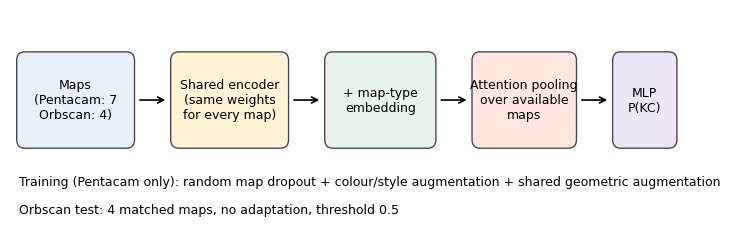

In [5]:
fig, ax = plt.subplots(figsize=(7.2, 2.3)); ax.set_xlim(0, 100); ax.set_ylim(0, 30); ax.axis("off"); ax.grid(False)
def box(x, w, t, fc):
    ax.add_patch(FancyBboxPatch((x, 11), w, 13, boxstyle="round,pad=0.3,rounding_size=1.2", fc=fc, ec="#444", lw=.8))
    ax.text(x + w / 2, 17.5, t, ha="center", va="center", fontsize=7.5)
def arr(x0, x1): ax.annotate("", xy=(x1, 17.5), xytext=(x0, 17.5), arrowprops=dict(arrowstyle="->", lw=1))
for x, w, t, fc in [(1, 17, "Maps\n(Pentacam: 7\nOrbscan: 4)", "#E8F1FA"), (24, 17, "Shared encoder\n(same weights\nfor every map)", "#FFF4D6"),
                    (47, 16, "+ map-type\nembedding", "#E6F4EA"), (69, 15, "Attention pooling\nover available\nmaps", "#FDE7E0"), (90, 9, "MLP\nP(KC)", "#EFE6F5")]: box(x, w, t, fc)
for a, b in [(18.6, 23.4), (41.6, 46.4), (63.6, 68.4), (84.6, 89.4)]: arr(a, b)
ax.text(1, 5.5, "Training (Pentacam only): random map dropout + colour/style augmentation + shared geometric augmentation", fontsize=7.5)
ax.text(1, 1.5, "Orbscan test: 4 matched maps, no adaptation, threshold 0.5", fontsize=7.5)
savefig(fig, "fig01_method")

In [6]:
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 1, 3, 1, 1)

def geo(x):  # same random affine for all maps of one eye
    B, dev = x.shape[0], x.device
    ang = (torch.rand(B, device=dev) - .5) * 2 * np.deg2rad(10)
    sc = 1 + (torch.rand(B, device=dev) - .5) * .1
    tx, ty = [(torch.rand(B, device=dev) - .5) * .1 for _ in range(2)]
    c, s = torch.cos(ang) / sc, torch.sin(ang) / sc
    theta = torch.stack([torch.stack([c, -s, tx], 1), torch.stack([s, c, ty], 1)], 1)
    xb = x.flatten(1, 2)
    g = F.affine_grid(theta, xb.shape, align_corners=False)
    return F.grid_sample(xb, g, padding_mode="border", align_corners=False).view_as(x)

def style(x):  # device-style augmentation
    B, V, _, H, W = x.shape; dev = x.device
    r = lambda lo, hi: torch.rand(B, 1, 1, 1, 1, device=dev) * (hi - lo) + lo
    perm = torch.stack([torch.randperm(3, device=dev) if random.random() < .3 else torch.arange(3, device=dev) for _ in range(B)])
    x = torch.gather(x, 2, perm.view(B, 1, 3, 1, 1).expand(B, V, 3, H, W))
    gray = x.mean(2, keepdim=True)
    x = gray + (x - gray) * r(.5, 1.5)
    mu = x.mean((1, 2, 3, 4), keepdim=True)
    x = (x - mu) * r(.7, 1.3) + mu * r(.8, 1.2)
    x = x.clamp(0, 1) ** r(.8, 1.25)
    return (x + torch.randn_like(x) * r(0, .03)).clamp(0, 1)

def prep(X, rows, train, style_on):
    x = X[rows].to(DEVICE, non_blocking=True).float().div_(255)
    if train:
        x = geo(x)
        if style_on: x = style(x)
    return (x - MEAN.to(DEVICE)) / STD.to(DEVICE)

def sample_mask(B, V):
    m = torch.zeros(B, V, dtype=torch.bool)
    for i in range(B):
        u = random.random()
        if V == 7:
            if u < P_ALL: m[i] = True
            elif u < P_ALL + P_MATCHED: m[i, :4] = True
            else: m[i, torch.randperm(V)[:random.randint(1, V - 1)]] = True
        else:
            if u < .5: m[i] = True
            else: m[i, torch.randperm(V)[:random.randint(1, V - 1)]] = True
    return m

class ViewSetNet(nn.Module):
    def __init__(self, backbone, pool="attn", nv=7, pretrained=True):
        super().__init__()
        self.enc = timm.create_model(backbone, pretrained=pretrained, num_classes=0)
        d = getattr(self.enc, "head_hidden_size", None) or self.enc.num_features
        self.nv, self.pool = nv, pool
        self.vemb = nn.Parameter(torch.randn(nv, d) * .02)
        if pool == "attn": self.att = nn.Sequential(nn.Linear(d, 128), nn.Tanh(), nn.Linear(128, 1))
        self.head = nn.Sequential(nn.Linear(d, 256), nn.ReLU(), nn.Dropout(.3), nn.Linear(256, 1))

    def forward(self, x, vid, mask, keep_maps=False, return_att=False):
        B, V = mask.shape
        sel = mask.flatten().nonzero(as_tuple=True)[0]
        xs = x.flatten(0, 1)[sel]
        if keep_maps:
            maps = self.enc.forward_features(xs); maps.retain_grad(); self._maps = maps
            f = self.enc.forward_head(maps, pre_logits=True)
        else:
            f = self.enc(xs)
        h = torch.zeros(B * V, f.shape[1], device=f.device, dtype=f.dtype)
        h[sel] = f
        h = h.view(B, V, -1) + self.vemb[vid].unsqueeze(0).to(f.dtype)
        if self.pool == "attn":
            a = torch.softmax(self.att(h).squeeze(-1).float().masked_fill(~mask, -1e4), 1)
        else:
            a = mask.float() / mask.float().sum(1, keepdim=True)
        z = (a.unsqueeze(-1).to(h.dtype) * h).sum(1)
        out = self.head(z).squeeze(1)
        return (out, z, a) if return_att else out

## 3. Training and inference

In [7]:
@torch.no_grad()
def predict(model, X, rows, keep, bs=32):
    model.eval(); P, Z, A = [], [], []
    for i in range(0, len(rows), bs):
        x = prep(X, rows[i:i + bs], False, False)[:, :model.nv]
        V = x.shape[1]
        mask = torch.zeros(len(x), V, dtype=torch.bool, device=DEVICE); mask[:, keep] = True
        with torch.autocast(device_type=DEVICE, enabled=USE_AMP):
            o, z, a = model(x, torch.arange(V, device=DEVICE), mask, return_att=True)
        P.append(torch.sigmoid(o.float()).cpu()); Z.append(z.float().cpu()); A.append(a.float().cpu())
    return torch.cat(P).numpy(), torch.cat(Z).numpy(), torch.cat(A).numpy()

@torch.no_grad()
def adabn_predict(model, X, rows, keep, bs=32):
    # test-time BatchNorm statistics adaptation on the unlabeled target images (BN backbones only)
    m = copy.deepcopy(model).eval()
    bns = [b for b in m.modules() if isinstance(b, nn.modules.batchnorm._BatchNorm)]
    if not bns: return None
    for b in bns: b.reset_running_stats(); b.momentum = None; b.train()
    for i in range(0, len(rows), bs):
        x = prep(X, rows[i:i + bs], False, False)[:, :m.nv]
        V = x.shape[1]
        mask = torch.zeros(len(x), V, dtype=torch.bool, device=DEVICE); mask[:, keep] = True
        with torch.autocast(device_type=DEVICE, enabled=USE_AMP): m(x, torch.arange(V, device=DEVICE), mask)
    return predict(m, X, rows, keep)[0]

CFGS = {
    "FULL":       dict(drop=True,  style=True,  pool="attn", nv=7),
    "noViewDrop": dict(drop=False, style=True,  pool="attn", nv=7),
    "noStyle":    dict(drop=True,  style=False, pool="attn", nv=7),
    "meanPool":   dict(drop=True,  style=True,  pool="mean", nv=7),
    "matched4":   dict(drop=False, style=True,  pool="attn", nv=4),
}
REV_CFG = dict(drop=True, style=True, pool="attn", nv=4)
SAVE = {"FULL", "noStyle"}     # weights kept for interpretation figures
M4 = [0, 1, 2, 3]

def fit(bb, c, X, y, tr_rows, va_rows, epochs, seed):
    set_seed(seed)
    model = ViewSetNet(bb, c["pool"], c["nv"], PRETRAINED).to(DEVICE)
    enc = list(model.enc.parameters())
    rest = [p for n, p in model.named_parameters() if not n.startswith("enc.")]
    opt = torch.optim.AdamW([{"params": enc, "lr": LR_BB}, {"params": rest, "lr": LR_HEAD}], weight_decay=1e-2)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=[LR_BB, LR_HEAD], total_steps=epochs * int(np.ceil(len(tr_rows) / BATCH)), pct_start=.1)
    amp = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    vid, nv, hist = torch.arange(c["nv"], device=DEVICE), c["nv"], []
    for ep in range(epochs):
        model.train(); perm = np.random.permutation(tr_rows); tl = 0
        for i in range(0, len(perm), BATCH):
            b = perm[i:i + BATCH]
            if len(b) < 2: continue
            x = prep(X, b, True, c["style"])[:, :nv]
            mask = (sample_mask(len(b), nv) if c["drop"] else torch.ones(len(b), nv, dtype=torch.bool)).to(DEVICE)
            yb = torch.tensor(y[b], dtype=torch.float32, device=DEVICE)
            with torch.autocast(device_type=DEVICE, enabled=USE_AMP): o = model(x, vid, mask)
            loss = F.binary_cross_entropy_with_logits(o.float(), yb)
            opt.zero_grad(set_to_none=True); amp.scale(loss).backward()
            amp.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            amp.step(opt); amp.update(); sched.step()
            tl += loss.item() * len(b)
        pv = predict(model, X, va_rows, list(range(nv)))[0]
        hist.append((tl / len(perm), roc_auc_score(y[va_rows], pv), accuracy_score(y[va_rows], pv >= .5)))
    return model, np.array(hist)

def run_cv(bb, cfg, seed):
    suffix = "" if seed == SEED else f"_seed{seed}"       # seed-42 name is unchanged so earlier runs can be reused
    name = f"pred_{bb}_{cfg}_s{IMG}_e{EPOCHS}{suffix}.npz"
    f = find(name)
    if f is not None:
        z = np.load(f); return {k: z[k] for k in z.files}
    c = CFGS[cfg]; keep_all = list(range(c["nv"]))
    oof = np.zeros(len(tv)); R = {k: [] for k in ["te_all", "te_m4", "ext", "ext_ada", "hist"]}
    for fo in FOLDS:
        t0 = time.time(); va = fold_tv == fo
        model, h = fit(bb, c, PEN_X, y_pen, tv[~va], tv[va], EPOCHS, seed)
        if cfg in SAVE and seed == SEED: torch.save(model.state_dict(), CACHE / f"w_{bb}_{cfg}_f{fo}.pt")
        oof[va] = predict(model, PEN_X, tv[va], keep_all)[0]
        R["te_all"].append(predict(model, PEN_X, te, keep_all)[0])
        R["te_m4"].append(predict(model, PEN_X, te, M4)[0])
        R["ext"].append(predict(model, ORB_X, ALL_ORB, M4)[0])
        a = adabn_predict(model, ORB_X, ALL_ORB, M4)
        R["ext_ada"].append(a if a is not None else np.full(len(orb), np.nan))
        R["hist"].append(h)
        print(f"{bb} {cfg} seed {seed} fold {fo}: val acc {h[-1, 2]:.4f} auc {h[-1, 1]:.4f} ({time.time() - t0:.0f}s)")
    out = {"oof": oof, **{k: np.stack(v) for k, v in R.items()}}
    np.savez(CACHE / name, **out)
    return out

In [8]:
def metrics(y, p, thr=.5):
    yh = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, yh, labels=[0, 1]).ravel()
    se, sp = tp / (tp + fn), tn / (tn + fp)
    return dict(acc=accuracy_score(y, yh), sens=se, spec=sp, bacc=(se + sp) / 2, f1=f1_score(y, yh), auc=roc_auc_score(y, p), mcc=matthews_corrcoef(y, yh))

def ece(y, p, bins=10):
    b = np.minimum((p * bins).astype(int), bins - 1)
    return sum((b == k).mean() * abs(y[b == k].mean() - p[b == k].mean()) for k in range(bins) if (b == k).any())

def youden(y, p):
    fpr, tpr, th = roc_curve(y, p); return th[np.argmax(tpr - fpr)]

def summarize(R):
    oof, o = R["oof"], {}
    fa = [accuracy_score(y_tv[fold_tv == f], oof[fold_tv == f] >= .5) for f in FOLDS]
    fu = [roc_auc_score(y_tv[fold_tv == f], oof[fold_tv == f]) for f in FOLDS]
    m = metrics(y_tv[ran], oof[ran]); o.update(cv_acc=m["acc"], cv_acc_sd=np.std(fa), cv_auc=m["auc"], cv_auc_sd=np.std(fu))
    for tag, p in [("te7", R["te_all"].mean(0)), ("te4", R["te_m4"].mean(0))]:
        m = metrics(y_te, p); o.update({f"{tag}_acc": m["acc"], f"{tag}_auc": m["auc"]})
    m = metrics(y_orb, R["ext"].mean(0)); o.update({f"ext_{k}": v for k, v in m.items()})
    if not np.isnan(R["ext_ada"]).any():
        m = metrics(y_orb, R["ext_ada"].mean(0)); o.update(extA_acc=m["acc"], extA_auc=m["auc"])
    return o

def cluster_boot(preds, y, g, n=N_BOOT):
    # preds[name] = list of prediction vectors (one per seed); the statistic is the mean over seeds.
    # Resampling is by patient (Orbscan) or by case (Pentacam), so both eyes of a patient stay together.
    rng = np.random.default_rng(SEED); ug = np.unique(g); by = {k: np.where(g == k)[0] for k in ug}
    out = {k: {"acc": [], "auc": []} for k in preds}
    for _ in range(n):
        ii = np.concatenate([by[k] for k in rng.choice(ug, len(ug))])
        if len(np.unique(y[ii])) < 2: continue
        for k, pl in preds.items():
            out[k]["acc"].append(np.mean([((p[ii] >= .5) == y[ii]).mean() for p in pl]))
            out[k]["auc"].append(np.mean([roc_auc_score(y[ii], p[ii]) for p in pl]))
    return {k: {m: np.array(v) for m, v in d.items()} for k, d in out.items()}

def boot_metrics(y, p, g, thr=.5, n=N_BOOT):
    rng = np.random.default_rng(SEED); ug = np.unique(g); by = {k: np.where(g == k)[0] for k in ug}; out = []
    for _ in range(n):
        ii = np.concatenate([by[k] for k in rng.choice(ug, len(ug))])
        if len(np.unique(y[ii])) < 2: continue
        out.append(metrics(y[ii], p[ii], thr))
    return pd.DataFrame(out)

ci = lambda v: f"{np.mean(v):.3f} [{np.percentile(v, 2.5):.3f}, {np.percentile(v, 97.5):.3f}]"

## 4. Backbone selection

The backbone is chosen by cross-validation accuracy on Pentacam only. Orbscan results are shown for completeness and are not used for the choice.

In [9]:
RES = {}
for bb in BACKBONES: RES[(bb, "FULL", SEED)] = run_cv(bb, "FULL", SEED)
tab_bb = pd.DataFrame({bb: summarize(RES[(bb, "FULL", SEED)]) for bb in BACKBONES}).T
BEST = tab_bb.sort_values(["cv_acc", "cv_auc"], ascending=False).index[0]
print("selected by cross-validation:", BEST)
keep("table_backbones", tab_bb.round(4))

model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

resnet50 FULL seed 42 fold 1: val acc 1.0000 auc 1.0000 (163s)
resnet50 FULL seed 42 fold 2: val acc 0.9833 auc 0.9978 (163s)
resnet50 FULL seed 42 fold 3: val acc 0.9833 auc 1.0000 (163s)
resnet50 FULL seed 42 fold 4: val acc 0.9833 auc 1.0000 (163s)
resnet50 FULL seed 42 fold 5: val acc 0.9667 auc 0.9844 (164s)


model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

efficientnet_b0 FULL seed 42 fold 1: val acc 1.0000 auc 1.0000 (500s)
efficientnet_b0 FULL seed 42 fold 2: val acc 0.9833 auc 1.0000 (102s)
efficientnet_b0 FULL seed 42 fold 3: val acc 1.0000 auc 1.0000 (102s)
efficientnet_b0 FULL seed 42 fold 4: val acc 1.0000 auc 1.0000 (102s)
efficientnet_b0 FULL seed 42 fold 5: val acc 0.9667 auc 0.9967 (102s)


... (6 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

swin_tiny_patch4_window7_224 FULL seed 42 fold 1: val acc 1.0000 auc 1.0000 (216s)
swin_tiny_patch4_window7_224 FULL seed 42 fold 2: val acc 0.9833 auc 1.0000 (215s)
swin_tiny_patch4_window7_224 FULL seed 42 fold 3: val acc 1.0000 auc 1.0000 (214s)
swin_tiny_patch4_window7_224 FULL seed 42 fold 4: val acc 1.0000 auc 1.0000 (216s)
swin_tiny_patch4_window7_224 FULL seed 42 fold 5: val acc 0.9667 auc 0.9956 (215s)
selected by cross-validation: convnext_tiny


,cv_acc,cv_acc_sd,cv_auc,cv_auc_sd,te7_acc,te7_auc,te4_acc,te4_auc,ext_acc,ext_sens,ext_spec,ext_bacc,ext_f1,ext_auc,ext_mcc,extA_acc,extA_auc
resnet50,0.9833,0.0105,0.9980,0.0061,0.95,0.9964,0.95,0.9944,0.8024,0.4664,1.0000,0.7332,0.6361,0.9706,0.5958,0.8351,0.9708
efficientnet_b0,0.9900,0.0133,0.9985,0.0013,0.95,0.9896,0.96,0.9820,0.7093,0.2169,0.9989,0.6079,0.3559,0.9681,0.3818,0.8394,0.9679
convnext_tiny,0.9933,0.0082,0.9996,0.0009,0.98,1.0000,0.98,1.0000,0.9375,0.9693,0.9187,0.9440,0.9199,0.9843,0.8718,NaN,NaN
densenet121,0.9800,0.0125,0.9998,0.0004,0.98,0.9992,0.99,0.9992,0.9048,0.7524,0.9944,0.8734,0.8540,0.9866,0.8012,0.9133,0.9819
swin_tiny_patch4_window7_224,0.9900,0.0133,0.9996,0.0018,0.98,1.0000,0.98,1.0000,0.9645,0.9271,0.9865,0.9568,0.9508,0.9860,0.9237,NaN,NaN


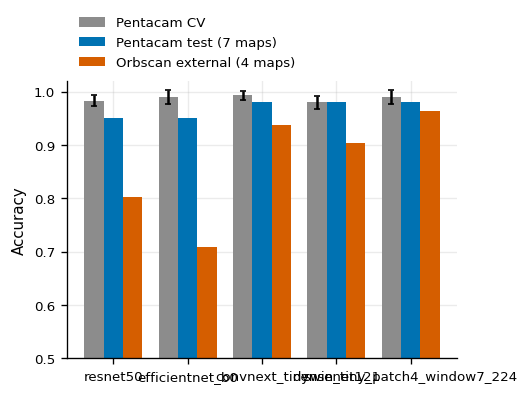

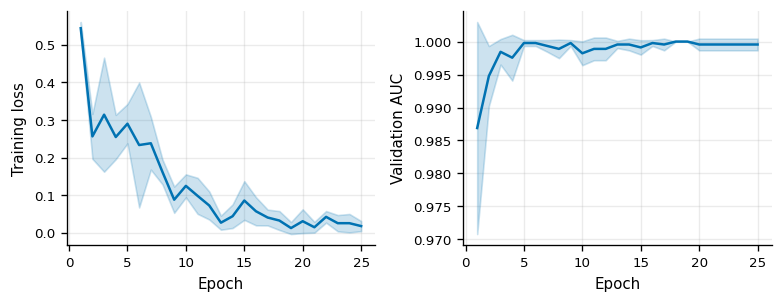

In [10]:
fig, ax = plt.subplots(figsize=(4.2, 3.0)); x = np.arange(len(BACKBONES)); w = .26
for k, (c, lab, col) in enumerate([("cv_acc", "Pentacam CV", COL["grey"]), ("te7_acc", "Pentacam test (7 maps)", COL["pen"]), ("ext_acc", "Orbscan external (4 maps)", COL["orb"])]):
    ax.bar(x + (k - 1) * w, tab_bb[c], w, color=col, label=lab, yerr=tab_bb["cv_acc_sd"] if c == "cv_acc" else None, capsize=2)
ax.set_xticks(x); ax.set_xticklabels(BACKBONES); ax.set_ylabel("Accuracy"); ax.set_ylim(.5, 1.02)
ax.legend(frameon=False, loc="lower left", bbox_to_anchor=(0, 1), ncol=1)
savefig(fig, "fig04_backbones_accuracy")

h = RES[(BEST, "FULL", SEED)]["hist"]; ep = np.arange(1, h.shape[1] + 1)
fig, ax = plt.subplots(1, 2, figsize=(6.6, 2.6))
for k, a, s in [(0, ax[0], "Training loss"), (1, ax[1], "Validation AUC")]:
    m, sd = h[:, :, k].mean(0), h[:, :, k].std(0)
    a.plot(ep, m, color=COL["pen"]); a.fill_between(ep, m - sd, m + sd, color=COL["pen"], alpha=.2); a.set_xlabel("Epoch"); a.set_ylabel(s)
plt.tight_layout(); savefig(fig, "figS1_training_curves")

## 5. Main result: zero-shot Orbscan validation

Threshold 0.5 is fixed in advance. For reference we also report the threshold that maximises Youden's J on the Pentacam cross-validation predictions, and the (non-deployable) Orbscan-optimal threshold.

In [11]:
R = RES[(BEST, "FULL", SEED)]
p_oof, p_te7, p_te4, p_ext = R["oof"], R["te_all"].mean(0), R["te_m4"].mean(0), R["ext"].mean(0)
thr_cv = youden(y_tv[ran], p_oof[ran])
case_te = np.arange(len(te))

def row(name, y, p, g, thr):
    b = boot_metrics(y, p, g, thr)
    return {"Evaluation": name, **{k.upper() if k in ("auc", "mcc") else k.capitalize(): ci(b[k]) for k in ["acc", "sens", "spec", "f1", "mcc", "auc"]}}
tab_main = pd.DataFrame([
    row("Pentacam test, 7 maps", y_te, p_te7, case_te, .5),
    row("Pentacam test, 4 matched maps", y_te, p_te4, case_te, .5),
    row("Orbscan external, 4 maps (threshold 0.5)", y_orb, p_ext, g_orb, .5),
    row(f"Orbscan external, Pentacam-CV threshold ({thr_cv:.2f})", y_orb, p_ext, g_orb, thr_cv)]).set_index("Evaluation")
keep("table2_main_results", tab_main); display(tab_main)

extra = pd.DataFrame([{"set": n, "ECE": ece(yy, pp), "Brier": brier_score_loss(yy, pp)} for n, yy, pp in
                      [("Pentacam test, 7 maps", y_te, p_te7), ("Orbscan external", y_orb, p_ext)]]).set_index("set")
keep("table2b_calibration", extra.round(4)); display(extra.round(4))

,Acc,Sens,Spec,F1,MCC,AUC
Evaluation,,,,,,
"Pentacam test, 7 maps","0.980 [0.950, 1.000]","0.960 [0.902, 1.000]","1.000 [1.000, 1.000]","0.979 [0.948, 1.000]","0.961 [0.904, 1.000]","1.000 [1.000, 1.000]"
"Pentacam test, 4 matched maps","0.980 [0.950, 1.000]","0.960 [0.902, 1.000]","1.000 [1.000, 1.000]","0.979 [0.948, 1.000]","0.961 [0.904, 1.000]","1.000 [1.000, 1.000]"
"Orbscan external, 4 maps (threshold 0.5)","0.937 [0.923, 0.951]","0.969 [0.951, 0.985]","0.919 [0.897, 0.938]","0.920 [0.898, 0.938]","0.872 [0.842, 0.900]","0.984 [0.974, 0.992]"
"Orbscan external, Pentacam-CV threshold (0.03)","0.583 [0.551, 0.613]","0.994 [0.987, 1.000]","0.341 [0.307, 0.377]","0.639 [0.602, 0.673]","0.393 [0.363, 0.425]","0.984 [0.974, 0.992]"


,ECE,Brier
set,,
"Pentacam test, 7 maps",0.0247,0.0207
Orbscan external,0.1052,0.0586


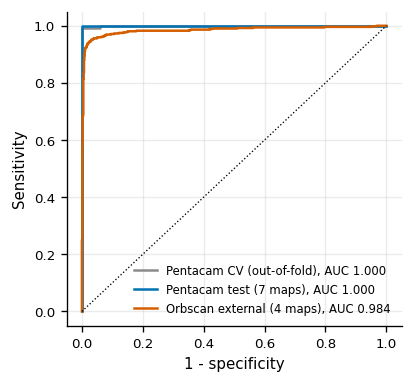

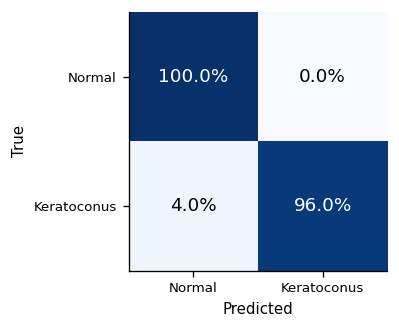

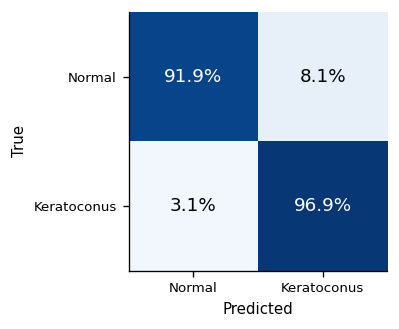

,TN,FP,FN,TP
Pentacam independent test (7 maps),50,0,2,48
Orbscan external (4 maps),814,72,16,505


In [12]:
fig, ax = plt.subplots(figsize=(3.6, 3.4))
for nm, yy, pp, c in [("Pentacam CV (out-of-fold)", y_tv[ran], p_oof[ran], COL["grey"]), ("Pentacam test (7 maps)", y_te, p_te7, COL["pen"]), ("Orbscan external (4 maps)", y_orb, p_ext, COL["orb"])]:
    fpr, tpr, _ = roc_curve(yy, pp); ax.plot(fpr, tpr, color=c, label=f"{nm}, AUC {roc_auc_score(yy, pp):.3f}")
ax.plot([0, 1], [0, 1], ":", color="k", lw=.8); ax.set_xlabel("1 - specificity"); ax.set_ylabel("Sensitivity")
ax.legend(frameon=False, loc="lower right", fontsize=7); savefig(fig, "fig05_roc")

# Normalised confusion matrices (rows sum to 100%); raw counts are saved to tables/cm_counts.csv for the text.
cms = {}
for nm, yy, pp, name in [("Pentacam independent test (7 maps)", y_te, p_te7, "fig06_cm_pentacam_test"), ("Orbscan external (4 maps)", y_orb, p_ext, "fig07_cm_orbscan")]:
    cm = confusion_matrix(yy, pp >= .5, labels=[0, 1]); cms[nm] = cm; cmn = cm / cm.sum(1, keepdims=True)
    fig, ax = plt.subplots(figsize=(3.0, 2.8)); ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1); ax.grid(False)
    for i in range(2):
        for j in range(2): ax.text(j, i, f"{100 * cmn[i, j]:.1f}%", ha="center", va="center", fontsize=11, color="white" if cmn[i, j] > .5 else "black")
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1]); ax.set_xticklabels(["Normal", "Keratoconus"]); ax.set_yticklabels(["Normal", "Keratoconus"])
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); savefig(fig, name)
keep("cm_counts", pd.DataFrame({k: dict(TN=v[0, 0], FP=v[0, 1], FN=v[1, 0], TP=v[1, 1]) for k, v in cms.items()}).T)
display(TABLES["cm_counts"])

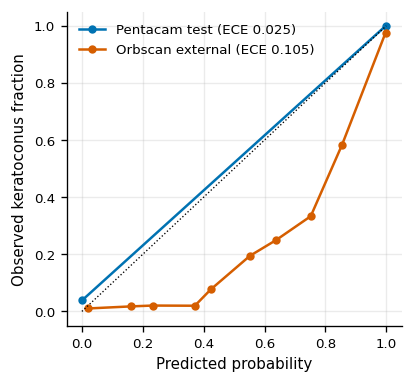

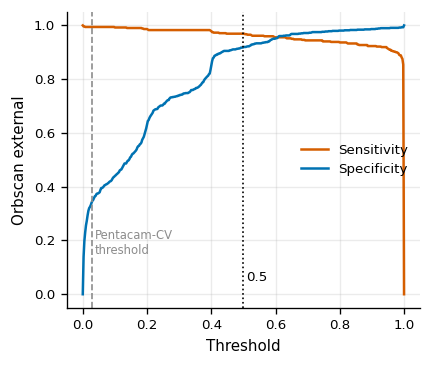

In [13]:
fig, ax = plt.subplots(figsize=(3.6, 3.4))
for nm, yy, pp, c in [("Pentacam test", y_te, p_te7, COL["pen"]), ("Orbscan external", y_orb, p_ext, COL["orb"])]:
    b = np.minimum((pp * 10).astype(int), 9); ok = [k for k in range(10) if (b == k).sum() >= 5]
    ax.plot([pp[b == k].mean() for k in ok], [yy[b == k].mean() for k in ok], "o-", color=c, ms=4, label=f"{nm} (ECE {ece(yy, pp):.3f})")
ax.plot([0, 1], [0, 1], ":", color="k", lw=.8); ax.set_xlabel("Predicted probability"); ax.set_ylabel("Observed keratoconus fraction")
ax.legend(frameon=False, loc="upper left"); savefig(fig, "fig08_calibration")

ts = np.linspace(0, 1, 401)
fig, ax = plt.subplots(figsize=(3.8, 3.2))
ax.plot(ts, [(p_ext[y_orb == 1] >= t).mean() for t in ts], color=COL["kc"], label="Sensitivity")
ax.plot(ts, [(p_ext[y_orb == 0] < t).mean() for t in ts], color=COL["normal"], label="Specificity")
ax.axvline(.5, color="k", ls=":", lw=1); ax.text(.51, .05, "0.5", fontsize=8)
ax.axvline(thr_cv, color=COL["grey"], ls="--", lw=1); ax.text(thr_cv + .01, .15, "Pentacam-CV\nthreshold", fontsize=7, color=COL["grey"])
ax.set_xlabel("Threshold"); ax.set_ylabel("Orbscan external"); ax.legend(frameon=False, loc="center right"); savefig(fig, "fig09_threshold_sweep")

## 6. Ablations

Each variant is trained with 3 seeds (same folds). Tables give mean ± SD over seeds; confidence intervals resample patients and average the statistic over seeds.

In [14]:
for cfg in CFGS:
    for s in SEEDS: RES[(BEST, cfg, s)] = run_cv(BEST, cfg, s)
per_seed = {cfg: pd.DataFrame([summarize(RES[(BEST, cfg, s)]) for s in SEEDS]) for cfg in CFGS}
msd = lambda cfg, c: f"{per_seed[cfg][c].mean():.3f} ± {per_seed[cfg][c].std(ddof=0):.3f}"
tab_ab = pd.DataFrame({cfg: {"Pentacam CV acc": msd(cfg, "cv_acc"), "Pentacam test AUC (4 maps)": msd(cfg, "te4_auc"),
                             "Orbscan acc": msd(cfg, "ext_acc"), "Orbscan AUC": msd(cfg, "ext_auc"), "Orbscan sens": msd(cfg, "ext_sens"),
                             "Orbscan spec": msd(cfg, "ext_spec"), "Orbscan MCC": msd(cfg, "ext_mcc")} for cfg in CFGS}).T
keep("table3_ablation", tab_ab); display(tab_ab)

ext_preds = {cfg: [RES[(BEST, cfg, s)]["ext"].mean(0) for s in SEEDS] for cfg in CFGS}
ada = [RES[(BEST, "FULL", s)]["ext_ada"].mean(0) for s in SEEDS]
if not any(np.isnan(a).any() for a in ada): ext_preds["FULL+AdaBN"] = ada
bo = cluster_boot(ext_preds, y_orb, g_orb)
bp = cluster_boot({cfg: [RES[(BEST, cfg, s)]["te_m4"].mean(0) for s in SEEDS] for cfg in CFGS}, y_te, case_te)
names = list(ext_preds)
tab_ci = pd.DataFrame({"Orbscan acc [95% CI]": {k: ci(bo[k]["acc"]) for k in names}, "Orbscan AUC [95% CI]": {k: ci(bo[k]["auc"]) for k in names},
                       "Pentacam test AUC, 4 maps [95% CI]": {k: ci(bp[k]["auc"]) for k in CFGS}})
tab_diff = pd.DataFrame({f"FULL - {k}": {"acc": ci(bo["FULL"]["acc"] - bo[k]["acc"]), "AUC": ci(bo["FULL"]["auc"] - bo[k]["auc"])} for k in names if k != "FULL"}).T
keep("table3b_ablation_ci", tab_ci); keep("table3c_paired_differences", tab_diff); display(tab_ci); display(tab_diff)

convnext_tiny FULL seed 43 fold 1: val acc 1.0000 auc 1.0000 (228s)
convnext_tiny FULL seed 43 fold 2: val acc 0.9833 auc 0.9978 (165s)
convnext_tiny FULL seed 43 fold 3: val acc 1.0000 auc 1.0000 (165s)
convnext_tiny FULL seed 43 fold 4: val acc 0.9833 auc 1.0000 (165s)
convnext_tiny FULL seed 43 fold 5: val acc 1.0000 auc 1.0000 (165s)
convnext_tiny FULL seed 44 fold 1: val acc 0.9833 auc 1.0000 (191s)
convnext_tiny FULL seed 44 fold 2: val acc 0.9833 auc 0.9989 (164s)
convnext_tiny FULL seed 44 fold 3: val acc 1.0000 auc 1.0000 (165s)
convnext_tiny FULL seed 44 fold 4: val acc 1.0000 auc 1.0000 (165s)
convnext_tiny FULL seed 44 fold 5: val acc 0.9833 auc 0.9989 (166s)
convnext_tiny noViewDrop seed 42 fold 1: val acc 1.0000 auc 1.0000 (238s)
convnext_tiny noViewDrop seed 42 fold 2: val acc 0.9833 auc 0.9978 (224s)
convnext_tiny noViewDrop seed 42 fold 3: val acc 0.9667 auc 1.0000 (224s)
convnext_tiny noViewDrop seed 42 fold 4: val acc 1.0000 auc 1.0000 (225s)
convnext_tiny noViewDrop

,Pentacam CV acc,Pentacam test AUC (4 maps),Orbscan acc,Orbscan AUC,Orbscan sens,Orbscan spec,Orbscan MCC
FULL,0.992 ± 0.002,1.000 ± 0.000,0.918 ± 0.014,0.986 ± 0.001,0.974 ± 0.004,0.884 ± 0.025,0.837 ± 0.025
noViewDrop,0.989 ± 0.002,0.999 ± 0.001,0.842 ± 0.090,0.982 ± 0.001,0.971 ± 0.013,0.766 ± 0.150,0.724 ± 0.128
noStyle,0.988 ± 0.003,1.000 ± 0.000,0.935 ± 0.009,0.989 ± 0.001,0.968 ± 0.014,0.916 ± 0.020,0.868 ± 0.016
meanPool,0.990 ± 0.003,1.000 ± 0.000,0.962 ± 0.006,0.989 ± 0.000,0.953 ± 0.019,0.967 ± 0.017,0.919 ± 0.011
matched4,0.990 ± 0.000,0.999 ± 0.001,0.612 ± 0.214,0.974 ± 0.002,0.977 ± 0.024,0.397 ± 0.354,0.426 ± 0.281


,Orbscan acc [95% CI],Orbscan AUC [95% CI],"Pentacam test AUC, 4 maps [95% CI]"
FULL,"0.917 [0.901, 0.931]","0.986 [0.978, 0.993]","1.000 [1.000, 1.000]"
noViewDrop,"0.842 [0.823, 0.858]","0.982 [0.972, 0.990]","0.999 [0.997, 1.000]"
noStyle,"0.936 [0.921, 0.949]","0.989 [0.984, 0.994]","1.000 [1.000, 1.000]"
meanPool,"0.962 [0.951, 0.971]","0.989 [0.983, 0.994]","1.000 [0.999, 1.000]"
matched4,"0.612 [0.589, 0.635]","0.974 [0.961, 0.984]","0.999 [0.996, 1.000]"


,acc,AUC
FULL - noViewDrop,"0.076 [0.064, 0.087]","0.004 [0.002, 0.007]"
FULL - noStyle,"-0.018 [-0.032, -0.005]","-0.003 [-0.008, 0.001]"
FULL - meanPool,"-0.044 [-0.056, -0.033]","-0.003 [-0.007, -0.000]"
FULL - matched4,"0.305 [0.283, 0.326]","0.012 [0.007, 0.018]"


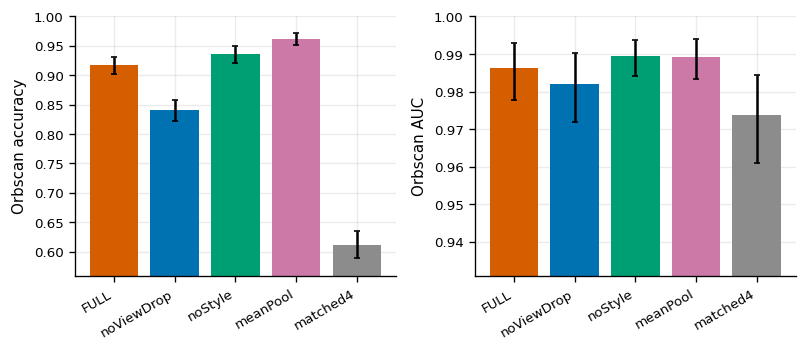

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(6.8, 3.0))
for a, m, lab in [(ax[0], "acc", "Orbscan accuracy"), (ax[1], "auc", "Orbscan AUC")]:
    mean = np.array([bo[k][m].mean() for k in names]); lo = np.array([np.percentile(bo[k][m], 2.5) for k in names]); hi = np.array([np.percentile(bo[k][m], 97.5) for k in names])
    a.bar(range(len(names)), mean, yerr=[mean - lo, hi - mean], capsize=2, color=[CFG_COL.get(k, COL["gold"]) for k in names])
    a.set_xticks(range(len(names))); a.set_xticklabels(names, rotation=30, ha="right"); a.set_ylabel(lab); a.set_ylim(max(.3, lo.min() - .03), 1.0)
plt.tight_layout(); savefig(fig, "fig10_ablation")

## 7. Few-shot threshold calibration

A small number of labelled Orbscan eyes (half per class) is used only to pick the decision threshold (maximum balanced accuracy, in logit space). All eyes of the calibration patients are removed from the evaluation. Results are averaged over random draws. 0 shots = fixed threshold 0.5.

,FULL,meanPool,noStyle,noViewDrop,matched4
0 eyes,0.937 ± 0.000,0.963 ± 0.000,0.923 ± 0.000,0.718 ± 0.000,0.421 ± 0.000
10 eyes,0.949 ± 0.036,0.942 ± 0.025,0.948 ± 0.038,0.927 ± 0.041,0.950 ± 0.026
20 eyes,0.953 ± 0.024,0.945 ± 0.026,0.950 ± 0.030,0.940 ± 0.025,0.949 ± 0.017
50 eyes,0.956 ± 0.013,0.949 ± 0.014,0.956 ± 0.014,0.951 ± 0.013,0.951 ± 0.016
100 eyes,0.957 ± 0.010,0.954 ± 0.011,0.957 ± 0.014,0.955 ± 0.012,0.954 ± 0.012


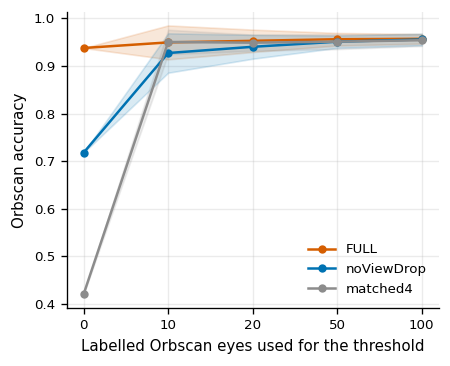

In [16]:
logit = lambda p: np.log(np.clip(p, 1e-6, 1 - 1e-6) / (1 - np.clip(p, 1e-6, 1 - 1e-6)))

def best_thr(y, z):
    s = np.unique(z); cand = np.r_[s[0] - 1e-3, (s[:-1] + s[1:]) / 2, s[-1] + 1e-3]
    sens = (z[y == 1][None, :] >= cand[:, None]).mean(1); spec = (z[y == 0][None, :] < cand[:, None]).mean(1)
    b = (sens + spec) / 2
    return np.median(cand[b >= b.max() - 1e-12])

def fewshot(p, k, draws=N_DRAWS, seed=SEED):
    rng = np.random.default_rng(seed); z = logit(p); i1, i0 = np.where(y_orb == 1)[0], np.where(y_orb == 0)[0]; out = []
    for _ in range(1 if k == 0 else draws):
        if k == 0: thr, test = 0., np.ones(len(z), bool)
        else:
            cal = np.r_[rng.choice(i1, k // 2, replace=False), rng.choice(i0, k - k // 2, replace=False)]
            test = ~np.isin(g_orb, g_orb[cal]); thr = best_thr(y_orb[cal], z[cal])
        yh = z[test] >= thr; yt = y_orb[test]
        se, sp = yh[yt == 1].mean(), (~yh[yt == 0]).mean()
        out.append((accuracy_score(yt, yh), (se + sp) / 2, se, sp))
    return np.array(out)

FS = {}
for cfg in ["FULL", "meanPool", "noStyle", "noViewDrop", "matched4"]:
    p = RES[(BEST, cfg, SEED)]["ext"].mean(0)
    for k in SHOTS: FS[(cfg, k)] = fewshot(p, k)
tab_fs = pd.DataFrame({cfg: {f"{k} eyes": f"{FS[(cfg, k)][:, 0].mean():.3f} ± {FS[(cfg, k)][:, 0].std():.3f}" for k in SHOTS} for cfg in ["FULL", "meanPool", "noStyle", "noViewDrop", "matched4"]})
keep("table5_fewshot_accuracy", tab_fs); display(tab_fs)

fig, ax = plt.subplots(figsize=(4.0, 3.2))
for cfg in ["FULL", "noViewDrop", "matched4"]:
    m = np.array([FS[(cfg, k)][:, 0].mean() for k in SHOTS]); s = np.array([FS[(cfg, k)][:, 0].std() for k in SHOTS])
    ax.plot(range(len(SHOTS)), m, "o-", color=CFG_COL[cfg], label=cfg, ms=4); ax.fill_between(range(len(SHOTS)), m - s, m + s, color=CFG_COL[cfg], alpha=.15)
ax.set_xticks(range(len(SHOTS))); ax.set_xticklabels(SHOTS); ax.set_xlabel("Labelled Orbscan eyes used for the threshold"); ax.set_ylabel("Orbscan accuracy")
ax.legend(frameon=False, loc="lower right"); savefig(fig, "fig11_fewshot")

## 8. Map analysis

In [17]:
def load_model(bb, cfg, fold):
    m = ViewSetNet(bb, CFGS[cfg]["pool"], CFGS[cfg]["nv"], False).to(DEVICE)
    m.load_state_dict(torch.load(find(f"w_{bb}_{cfg}_f{fold}.pt"), map_location=DEVICE)); return m.eval()

rs = np.random.RandomState(SEED)
pen_sub = {(i,) for i in range(7)} | {tuple(j for j in range(7) if j != i) for i in range(7)} | {(0, 1, 2, 3), tuple(range(7))}
pen_sub |= {tuple(sorted(rs.choice(7, k, replace=False))) for k in range(2, 7) for _ in range(10)}
orb_sub = [s for k in range(1, 5) for s in itertools.combinations(range(4), k)]
mods = [load_model(BEST, "FULL", f) for f in FOLDS]
sp = {s: np.mean([predict(m, PEN_X, te, list(s))[0] for m in mods], 0) for s in sorted(pen_sub)}
so = {s: np.mean([predict(m, ORB_X, ALL_ORB, list(s))[0] for m in mods], 0) for s in orb_sub}
df_p = pd.DataFrame([{"views": s, "k": len(s), "auc": roc_auc_score(y_te, p)} for s, p in sp.items()])
df_o = pd.DataFrame([{"views": s, "k": len(s), "auc": roc_auc_score(y_orb, p), "acc": ((p >= .5) == y_orb).mean()} for s, p in so.items()])
keep("view_subsets_pentacam", df_p.assign(views=df_p.views.astype(str))); keep("view_subsets_orbscan", df_o.assign(views=df_o.views.astype(str)))

,views,k,auc,acc
0,"(0,)",1,0.920757,0.852878
1,"(1,)",1,0.969459,0.862118
2,"(2,)",1,0.981180,0.742004
3,"(3,)",1,0.799307,0.680881
4,"(0, 1)",2,0.981608,0.918266
5,"(0, 2)",2,0.985061,0.850036
6,"(0, 3)",2,0.953452,0.800284
7,"(1, 2)",2,0.985041,0.816631
8,"(1, 3)",2,0.964730,0.929638
9,"(2, 3)",2,0.972950,0.909026


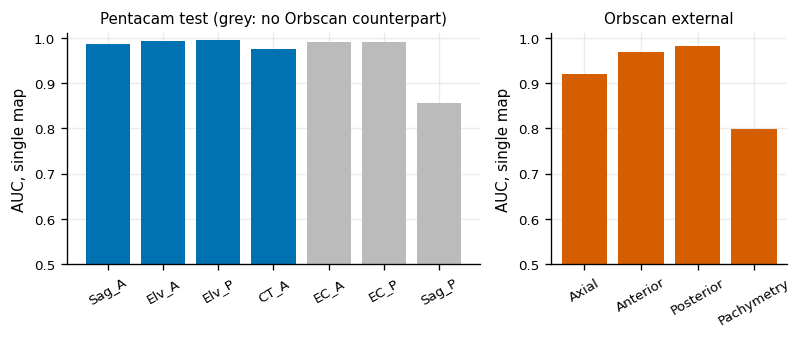

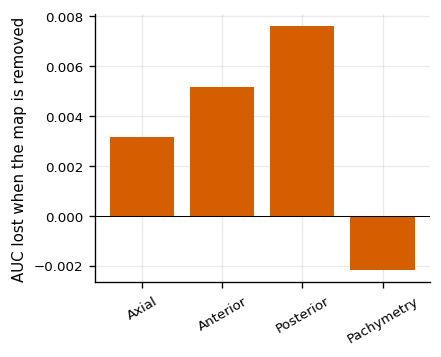

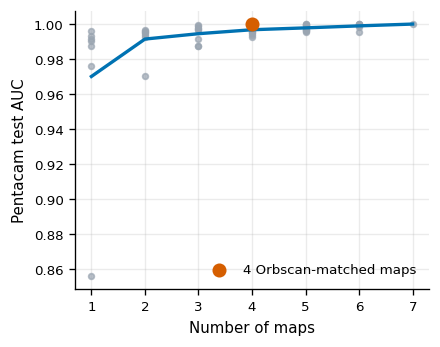

In [18]:
s1 = df_p[df_p.k == 1].sort_values("views"); o1 = df_o[df_o.k == 1].sort_values("views")
fig, ax = plt.subplots(1, 2, figsize=(6.8, 2.9), gridspec_kw=dict(width_ratios=[7, 4]))
ax[0].bar([PEN_VIEWS[v[0]] for v in s1.views], s1.auc, color=[COL["pen"] if v[0] < 4 else "#BBBBBB" for v in s1.views]); ax[0].set_title("Pentacam test (grey: no Orbscan counterpart)")
ax[1].bar([ORB_VIEWS[v[0]] for v in o1.views], o1.auc, color=COL["orb"]); ax[1].set_title("Orbscan external")
for a in ax: a.set_ylabel("AUC, single map"); a.set_ylim(.5, 1.01); a.tick_params(axis="x", rotation=30)
plt.tight_layout(); savefig(fig, "fig12_single_map")

full4 = df_o[df_o.k == 4].auc.iloc[0]
drop = [full4 - df_o[df_o.views == tuple(j for j in range(4) if j != i)].auc.iloc[0] for i in range(4)]
fig, ax = plt.subplots(figsize=(3.6, 2.9)); ax.bar(ORB_VIEWS, drop, color=COL["orb"]); ax.axhline(0, color="k", lw=.6)
ax.set_ylabel("AUC lost when the map is removed"); ax.tick_params(axis="x", rotation=30); savefig(fig, "fig13_leave_one_map_out")

fig, ax = plt.subplots(figsize=(3.8, 3.0))
for k in range(1, 8): v = df_p[df_p.k == k].auc; ax.scatter(np.full(len(v), k), v, s=12, color="#9AA5B1", alpha=.7)
ax.plot(df_p.groupby("k").auc.mean(), color=COL["pen"], lw=2)
ax.scatter([4], [df_p[df_p.views == (0, 1, 2, 3)].auc.iloc[0]], s=55, color=COL["kc"], zorder=5, label="4 Orbscan-matched maps")
ax.set_xlabel("Number of maps"); ax.set_ylabel("Pentacam test AUC"); ax.legend(frameon=False, loc="lower right"); savefig(fig, "fig14_map_count")

## 9. Domain gap and interpretation

Embeddings are from the fold-1 models. The device classifier AUC (logistic regression separating Pentacam from Orbscan embeddings, cross-validated) quantifies the gap; it is expected to be high, the question is whether class structure is preserved across devices. Grad-CAM and attention weights use the same model.

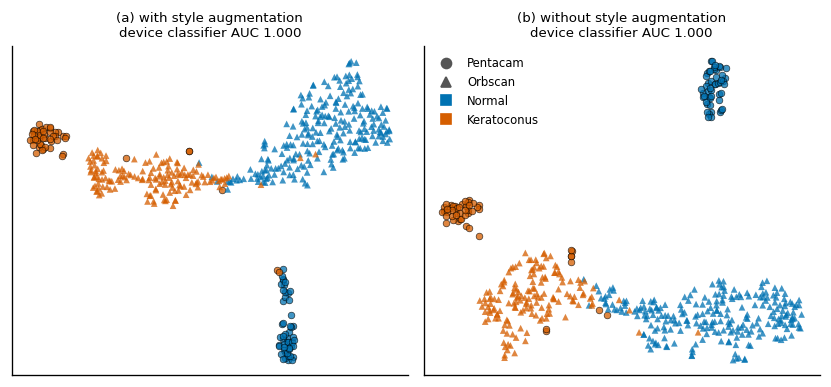

In [19]:
def domain_auc(Za, Zb):
    X = StandardScaler().fit_transform(np.r_[Za, Zb]); d = np.r_[np.zeros(len(Za)), np.ones(len(Zb))]
    p = cross_val_predict(LogisticRegression(max_iter=3000, class_weight="balanced"), X, d, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method="predict_proba")[:, 1]
    return roc_auc_score(d, p)

f0 = FOLDS[0]; sub = np.random.RandomState(SEED).choice(len(orb), min(len(orb), 400), replace=False); E = {}
for cfg in ["FULL", "noStyle"]:
    m = load_model(BEST, cfg, f0)
    E[cfg] = (predict(m, PEN_X, te, M4)[1], predict(m, ORB_X, sub, M4)[1], predict(m, PEN_X, te, M4)[2][:, :4], predict(m, ORB_X, sub, M4)[2])

fig, ax = plt.subplots(1, 2, figsize=(7.0, 3.3))
for a, cfg, tag in zip(ax, E, ["(a) with style augmentation", "(b) without style augmentation"]):
    zp, zo = E[cfg][:2]; Z = np.r_[zp, zo]
    T = TSNE(2, perplexity=min(30, (len(Z) - 1) / 3), random_state=SEED, init="pca").fit_transform(Z)
    lab, dev = np.r_[y_te, y_orb[sub]], np.r_[np.zeros(len(zp)), np.ones(len(zo))]
    for d_, l_, mk in [(0, 0, "o"), (0, 1, "o"), (1, 0, "^"), (1, 1, "^")]:
        s = (dev == d_) & (lab == l_)
        a.scatter(T[s, 0], T[s, 1], marker=mk, s=16, color=COL["normal"] if l_ == 0 else COL["kc"], alpha=.75, edgecolor="k" if d_ == 0 else "none", linewidth=.4)
    a.set_title(f"{tag}\ndevice classifier AUC {domain_auc(zp, zo):.3f}", fontsize=8); a.set_xticks([]); a.set_yticks([]); a.grid(False)
h_ = [plt.Line2D([], [], marker=m, ls="", color="#555", label=l) for m, l in [("o", "Pentacam"), ("^", "Orbscan")]] + [plt.Line2D([], [], marker="s", ls="", color=c, label=l) for c, l in [(COL["normal"], "Normal"), (COL["kc"], "Keratoconus")]]
ax[1].legend(handles=h_, frameon=False, fontsize=7, loc="best"); plt.tight_layout(); savefig(fig, "fig15_embedding")

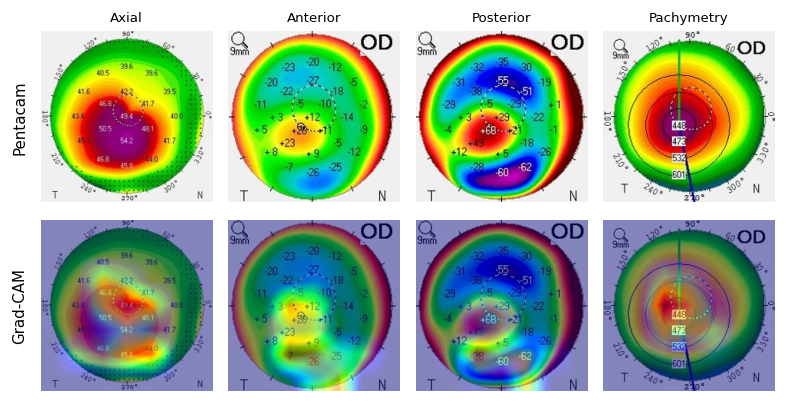

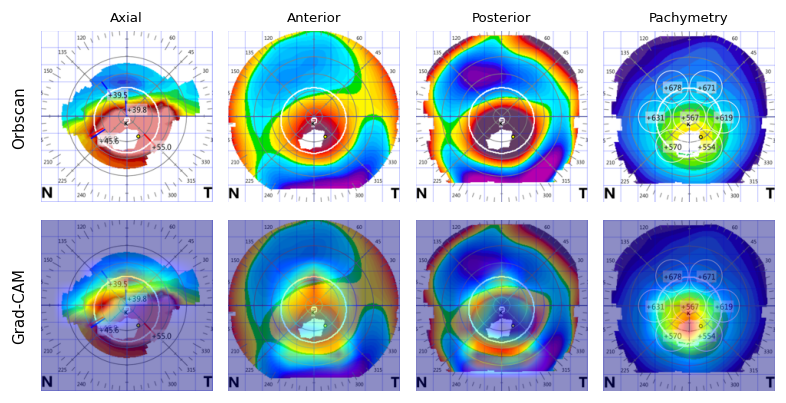

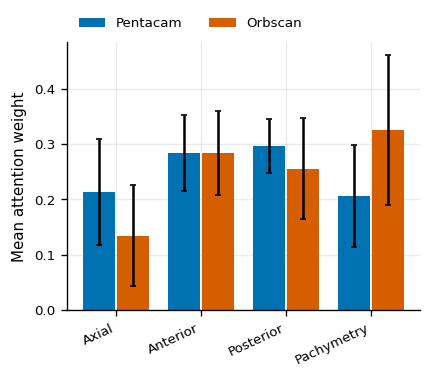

In [20]:
def cam_for(model, X, idx):
    model.eval(); model.zero_grad()
    x = prep(X, [idx], False, False)[:, :4].float()
    model(x, torch.arange(4, device=DEVICE), torch.ones(1, 4, dtype=torch.bool, device=DEVICE), keep_maps=True).sum().backward()
    mp = model._maps; w = mp.grad.mean((2, 3), keepdim=True)
    cam = F.interpolate(F.relu((w * mp).sum(1, keepdim=True)), size=(IMG, IMG), mode="bilinear", align_corners=False)[:, 0]
    lo, hi = cam.amin((1, 2), keepdim=True), cam.amax((1, 2), keepdim=True)
    return ((cam - lo) / (hi - lo + 1e-8)).detach().cpu().numpy()

model = load_model(BEST, "FULL", f0)
ip = te[np.where(y_te == 1)[0][np.argmax(p_te4[y_te == 1])]]; io = np.where(y_orb == 1)[0][np.argmax(p_ext[y_orb == 1])]
for X, i, tag, name in [(PEN_X, ip, "Pentacam", "fig16a_gradcam_pentacam"), (ORB_X, io, "Orbscan", "fig16b_gradcam_orbscan")]:
    cam = cam_for(model, X, i)
    fig, ax = plt.subplots(2, 4, figsize=(6.6, 3.5))
    for c in range(4):
        im = X[i, c].permute(1, 2, 0).numpy()
        ax[0, c].imshow(im); ax[1, c].imshow(im); ax[1, c].imshow(cam[c], cmap="jet", alpha=.45); ax[0, c].set_title(ORB_VIEWS[c], fontsize=8)
    for a in ax.ravel(): a.axis("off"); a.grid(False)
    ax[0, 0].text(-.08, .5, tag, transform=ax[0, 0].transAxes, rotation=90, va="center", ha="right", fontsize=9)
    ax[1, 0].text(-.08, .5, "Grad-CAM", transform=ax[1, 0].transAxes, rotation=90, va="center", ha="right", fontsize=9)
    plt.tight_layout(); savefig(fig, name)

ap, ao = E["FULL"][2], E["FULL"][3]; x_ = np.arange(4)
fig, ax = plt.subplots(figsize=(3.8, 2.9))
ax.bar(x_ - .2, ap.mean(0), .38, yerr=ap.std(0), capsize=2, color=COL["pen"], label="Pentacam"); ax.bar(x_ + .2, ao.mean(0), .38, yerr=ao.std(0), capsize=2, color=COL["orb"], label="Orbscan")
ax.set_xticks(x_); ax.set_xticklabels(ORB_VIEWS, rotation=25, ha="right"); ax.set_ylabel("Mean attention weight"); ax.legend(frameon=False, loc="lower left", bbox_to_anchor=(0, 1), ncol=2)
savefig(fig, "fig17_attention")

## 10. Reverse direction: train on Orbscan, test on Pentacam

Same method (map dropout, style augmentation, attention pooling), 4 maps, patient-grouped 5-fold CV on Orbscan; the 400 Pentacam cases (4 matched maps) are never seen. This completes the 2×2 transfer table.

REV convnext_tiny fold 1: val acc 0.9858 auc 0.9993 (545s)
REV convnext_tiny fold 2: val acc 0.9785 auc 0.9963 (347s)
REV convnext_tiny fold 3: val acc 0.9859 auc 0.9980 (254s)
REV convnext_tiny fold 4: val acc 0.9928 auc 0.9957 (247s)
REV convnext_tiny fold 5: val acc 0.9755 auc 0.9971 (238s)


,Test: Pentacam,Test: Orbscan
Train: Pentacam,"1.000 [1.000, 1.000] | 0.980 [0.950, 1.000]","0.984 [0.974, 0.992] | 0.937 [0.923, 0.951]"
Train: Orbscan,"0.980 [0.968, 0.990] | 0.779 [0.738, 0.820]","0.995 [0.991, 0.998] | 0.984 [0.976, 0.990]"


cells: AUC [95% CI] | accuracy [95% CI]; diagonal = same-device (Pentacam: independent test, Orbscan: patient-grouped CV)


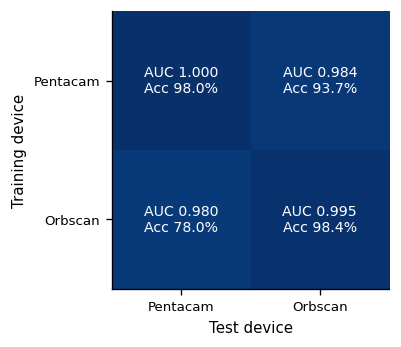

In [21]:
def run_reverse(bb):
    name = f"pred_REV_{bb}_s{IMG}_e{EPOCHS_REV}.npz"; f = find(name)
    if f is not None:
        z = np.load(f); return {k: z[k] for k in z.files}
    oof = np.zeros(len(orb)); pp = []; done = []
    for fo, (tr, va) in enumerate(StratifiedGroupKFold(5, shuffle=True, random_state=SEED).split(ALL_ORB, y_orb, g_orb), 1):
        if fo not in FOLDS: continue
        t0 = time.time(); model, h = fit(bb, REV_CFG, ORB_X, y_orb, tr, va, EPOCHS_REV, SEED)
        oof[va] = predict(model, ORB_X, va, M4)[0]; pp.append(predict(model, PEN_X, ALL_PEN, M4)[0]); done.append(va)
        print(f"REV {bb} fold {fo}: val acc {h[-1, 2]:.4f} auc {h[-1, 1]:.4f} ({time.time() - t0:.0f}s)")
    out = dict(oof=oof, pen=np.stack(pp), done=np.concatenate(done))
    np.savez(CACHE / name, **out); return out

if RUN_REVERSE:
    REV = run_reverse(BEST); p_rev = REV["pen"].mean(0); done = np.unique(REV["done"])
    cell = lambda yy, pp, gg: (lambda b: f"{ci(b['auc'])} | {ci(b['acc'])}")(boot_metrics(yy, pp, gg))
    tab_2x2 = pd.DataFrame({
        "Test: Pentacam": {"Train: Pentacam": cell(y_te, p_te4, case_te), "Train: Orbscan": cell(y_pen, p_rev, ALL_PEN)},
        "Test: Orbscan": {"Train: Pentacam": cell(y_orb, p_ext, g_orb), "Train: Orbscan": cell(y_orb[done], REV["oof"][done], g_orb[done])}})
    keep("table4_transfer_2x2", tab_2x2); display(tab_2x2)
    print("cells: AUC [95% CI] | accuracy [95% CI]; diagonal = same-device (Pentacam: independent test, Orbscan: patient-grouped CV)")

    A = np.array([[roc_auc_score(y_te, p_te4), roc_auc_score(y_orb, p_ext)], [roc_auc_score(y_pen, p_rev), roc_auc_score(y_orb[done], REV["oof"][done])]])
    Q = np.array([[((p_te4 >= .5) == y_te).mean(), ((p_ext >= .5) == y_orb).mean()], [((p_rev >= .5) == y_pen).mean(), ((REV["oof"][done] >= .5) == y_orb[done]).mean()]])
    fig, ax = plt.subplots(figsize=(3.8, 3.0)); ax.imshow(A, cmap="Blues", vmin=.5, vmax=1); ax.grid(False)
    for i in range(2):
        for j in range(2): ax.text(j, i, f"AUC {A[i, j]:.3f}\nAcc {100 * Q[i, j]:.1f}%", ha="center", va="center", fontsize=8.5, color="white" if A[i, j] > .85 else "black")
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1]); ax.set_xticklabels(["Pentacam", "Orbscan"]); ax.set_yticklabels(["Pentacam", "Orbscan"])
    ax.set_xlabel("Test device"); ax.set_ylabel("Training device"); savefig(fig, "fig18_transfer_matrix")

## 11. Export

In [22]:
L = []
def P(s): L.append(s); print(s)
P(f"Backbone (selected by Pentacam CV): {BEST}; epochs {EPOCHS}; image size {IMG}; ablation seeds {SEEDS}")
P("Pentacam: " + "; ".join(f"{i}: {r['Normal']} normal / {r['Keratoconus']} KC" for i, r in t1.iterrows() if 'Pentacam' in i))
P(f"Orbscan: {len(orb)} eyes, {orb.patient.nunique()} patients ({int((y_orb == 0).sum())} normal / {int((y_orb == 1).sum())} KC eyes)")
for k, v in cms.items(): P(f"Confusion counts, {k}: TN {v[0, 0]}, FP {v[0, 1]}, FN {v[1, 0]}, TP {v[1, 1]}")
P("\nMain results (95% CI):"); P(tab_main.to_string())
P("\nAblation (mean ± SD over seeds):"); P(tab_ab.to_string())
P("\nFew-shot accuracy:"); P(tab_fs.to_string())
if RUN_REVERSE: P("\nTransfer table (AUC | accuracy):"); P(tab_2x2.to_string())

with pd.ExcelWriter(TAB / "all_tables.xlsx") as xw:
    for n, t in TABLES.items(): t.to_excel(xw, sheet_name=n[:31])
pd.DataFrame({"eye_id": orb.eye_id, "patient": orb.patient, "label": y_orb, **{f"p_{k}_seed{s}": v for k, vs in ext_preds.items() for s, v in zip(SEEDS, vs)}}).to_csv(PRD / "orbscan_predictions.csv", index=False)
pd.DataFrame({"case_id": pen.case_id.values[te], "label": y_te, "p_7maps": p_te7, "p_4maps": p_te4}).to_csv(PRD / "pentacam_test_predictions.csv", index=False)
(OUT / "paper_numbers.txt").write_text("\n".join(L))
(OUT / "run_info.json").write_text(json.dumps(dict(torch=torch.__version__, timm=timm.__version__, seed=SEED, seeds=SEEDS, img=IMG, backbones=BACKBONES, best=BEST,
    epochs=EPOCHS, epochs_rev=EPOCHS_REV, batch=BATCH, lr_backbone=LR_BB, lr_head=LR_HEAD, p_all=P_ALL, p_matched=P_MATCHED, n_boot=N_BOOT, n_draws=N_DRAWS, shots=SHOTS), indent=1))

zip_path = OUT.parent / "keratoconus_results.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for d in [FIG, TAB, PRD] + ([CACHE] if INCLUDE_WEIGHTS else []):
        for f in sorted(d.rglob("*")):
            if f.is_file(): z.write(f, f.relative_to(OUT.parent))
    for f in ["paper_numbers.txt", "run_info.json"]: z.write(OUT / f, f"{OUT.name}/{f}")
print(f"\n{zip_path}  {zip_path.stat().st_size / 1e6:.1f} MB,", sum(1 for _ in zipfile.ZipFile(zip_path).namelist()), "files")

Backbone (selected by Pentacam CV): convnext_tiny; epochs 25; image size 224; ablation seeds [42, 43, 44]
Pentacam: Pentacam train/validation (cases): 150 normal / 150 KC; Pentacam independent test (cases): 50 normal / 50 KC
Orbscan: 1407 eyes, 744 patients (886 normal / 521 KC eyes)
Confusion counts, Pentacam independent test (7 maps): TN 50, FP 0, FN 2, TP 48
Confusion counts, Orbscan external (4 maps): TN 814, FP 72, FN 16, TP 505

Main results (95% CI):
                                                                 Acc                  Sens                  Spec                    F1                   MCC                   AUC
Evaluation                                                                                                                                                                        
Pentacam test, 7 maps                           0.980 [0.950, 1.000]  0.960 [0.902, 1.000]  1.000 [1.000, 1.000]  0.979 [0.948, 1.000]  0.961 [0.904, 1.000]  1.000 [1.000, 1.000]
P